# Oasis Infobyte Data Analytics Internship
## Task 2: Customer Segmentation Analysis (RFM)
**Author:** Yasmeen Akhter  
**GitHub Repository:** OIBSIP  
**Tech Stack:** Python, Pandas, Scikit-Learn (KMeans), Matplotlib, Seaborn, Jupyter Notebook  

### Project Overview
This project applies K-Means clustering and RFM (Recency, Frequency, Monetary) analysis to segment an e-commerce customer base into distinct groups based on purchasing behaviour, enabling targeted marketing strategies.


### Step 1: Load Dataset and Inspect Structure
In this step, we load our e-commerce retail dataset, check its dimensions, data types, and verify if there are any missing values that need handling.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Dataset load karein
df = pd.read_csv('retail_sales_dataset.csv')

print("Rows and columns:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
display(df.head())

Rows and columns: (1000, 9)

Data types:
 Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

Missing values:
 Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


### Step 2: Descriptive Statistics
We calculate key metrics such as average purchase value, purchase frequency, and total spending to understand overall customer purchasing patterns.

In [3]:
print("Average Purchase Value (Mean Total Amount):", df['Total Amount'].mean())
print("Total Transactions:", df['Transaction ID'].count())
print("Unique Customers:", df['Customer ID'].nunique())

# Descriptive stats summary
display(df.describe())

Average Purchase Value (Mean Total Amount): 456.0
Total Transactions: 1000
Unique Customers: 1000


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


### Step 3: Feature Selection (RFM Analysis)
We extract Recency, Frequency, and Monetary (RFM) features for each unique customer to capture their purchasing behavior.

In [4]:
# Date ko datetime me convert karein aur snapshot date nikalien
df['Date'] = pd.to_datetime(df['Date'])
snapshot_date = df['Date'].max() + pd.Timedelta(days=1)

# RFM DataFrame banayein
rfm = df.groupby('Customer ID').agg({
    'Date': lambda x: (snapshot_date - x.max()).days,  # Recency
    'Transaction ID': 'count',                         # Frequency
    'Total Amount': 'sum'                              # Monetary
})

# Columns ke naam rename karein
rfm.rename(columns={
    'Date': 'Recency',
    'Transaction ID': 'Frequency',
    'Total Amount': 'Monetary'
}, inplace=True)

display(rfm.head())

,Recency,Frequency,Monetary
Customer ID,,,
CUST001,39,1,150
CUST002,309,1,1000
CUST003,354,1,30
CUST004,226,1,500
CUST005,241,1,100


### Step 4: Data Normalisation using StandardScaler
Since Recency and Monetary values are on completely different scales, we use StandardScaler to normalize the features so that K-Means gives equal weight to all variables.

In [5]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

# Scaled array ko wapas dataframe me badlein
rfm_scaled_df = pd.DataFrame(rfm_scaled, index=rfm.index, columns=['Recency', 'Frequency', 'Monetary'])
display(rfm_scaled_df.head())

,Recency,Frequency,Monetary
Customer ID,,,
CUST001,-1.368336,0.0,-0.546704
CUST002,1.197615,0.0,0.971919
CUST003,1.625274,0.0,-0.761098
CUST004,0.408823,0.0,0.078611
CUST005,0.551375,0.0,-0.636035


### Step 5: Optimal Clusters using the Elbow Method
We apply the Elbow Method to determine the optimal number of clusters (K) by calculating the Within-Cluster-Sum-of-Squares (WCSS) for different cluster values.

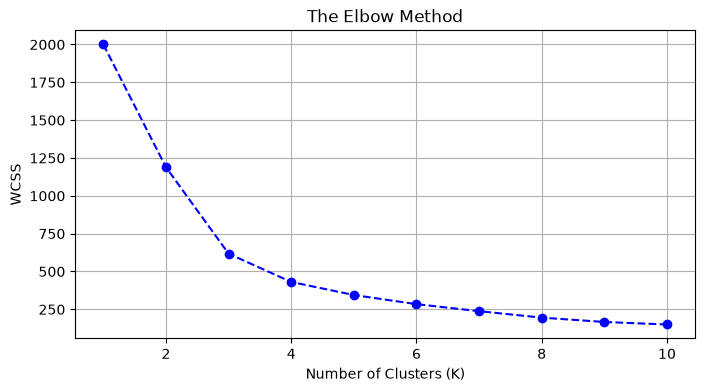

Cluster
1    392
0    380
2    228
Name: count, dtype: int64


In [6]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

# Elbow Plot
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--', color='b')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

# Optimal K (aam tor par 3 ya 4 select karte hain)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print(rfm['Cluster'].value_counts())

### Step 6: Cluster Visualisation & Profiling
We visualise our customer segments using scatter plots and calculate average RFM values per cluster to profile customer types.

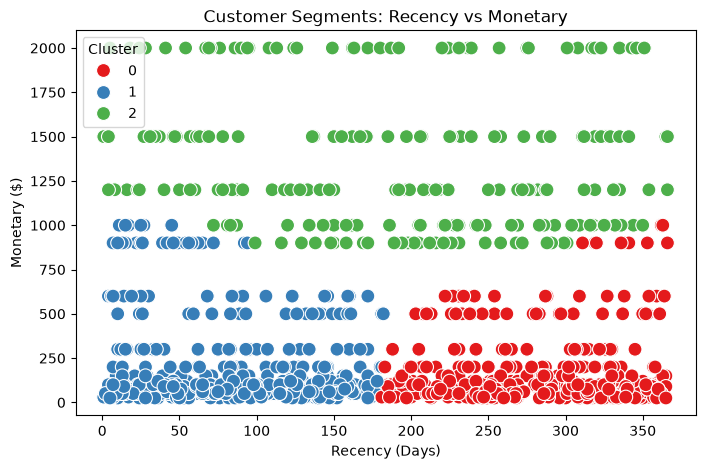

,Recency,Frequency,Monetary
Cluster,,,
0,275.347368,1.0,167.881579
1,87.755102,1.0,211.237245
2,192.763158,1.0,1357.017544


In [7]:
# Scatter Plot: Recency vs Monetary
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Recency', y='Monetary', hue='Cluster', data=rfm, palette='Set1', s=100)
plt.title('Customer Segments: Recency vs Monetary')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary ($)')
plt.legend(title='Cluster')
plt.show()

# Cluster Profile (Mean values)
cluster_profile = rfm.groupby('Cluster').mean()
display(cluster_profile)

### Step 7: Customer Count per Cluster
A bar chart showing the distribution of customers across different segments.

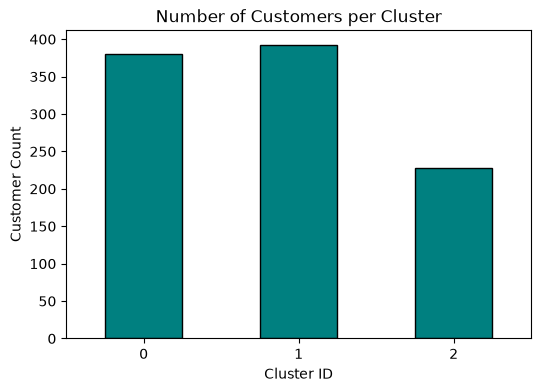

In [8]:
plt.figure(figsize=(6, 4))
rfm['Cluster'].value_counts().sort_index().plot(kind='bar', color='teal', edgecolor='black')
plt.title('Number of Customers per Cluster')
plt.xlabel('Cluster ID')
plt.ylabel('Customer Count')
plt.xticks(rotation=0)
plt.show()

### Step 8: Business Insights and Recommendations
Based on our customer segmentation:
1. **VIP / Loyal Segment**: Frequent buyers with high monetary value. **Recommendation:** Offer exclusive discounts, early access to sales, and loyalty rewards.
2. **At-Risk / Churned Segment**: Customers who haven't purchased in a long time. **Recommendation:** Send re-engagement emails with special "we miss you" discount vouchers.
3. **New / Occasional Segment**: Low frequency and low monetary value. **Recommendation:** Send onboarding campaigns and product recommendations to encourage repeat purchases.